<a href="https://colab.research.google.com/github/rohillatanisha676-del/CODSOFT_TASKNO/blob/main/Credit_Card_Fraud_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

print("=" * 60)
print("       CREDIT CARD FRAUD DETECTION PROJECT")
print("=" * 60)


       CREDIT CARD FRAUD DETECTION PROJECT


In [2]:
print("\nPlease upload your creditcard.csv file:")

uploaded = files.upload()

# Automatically get uploaded filename
filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)



Please upload your creditcard.csv file:


Saving fraudTest.csv (1).zip to fraudTest.csv (1) (1).zip

Dataset loaded successfully!
Dataset shape: (555719, 23)


In [3]:
print("\n" + "=" * 60)
print("DATASET INFORMATION")
print("=" * 60)

print("\nFirst 5 rows:")
print(df.head())

print("\nDataset columns:")
print(df.columns.tolist())

print("\nDataset information:")
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())



DATASET INFORMATION

First 5 rows:
   Unnamed: 0 trans_date_trans_time            cc_num  \
0           0   2020-06-21 12:14:25  2291163933867244   
1           1   2020-06-21 12:14:33  3573030041201292   
2           2   2020-06-21 12:14:53  3598215285024754   
3           3   2020-06-21 12:15:15  3591919803438423   
4           4   2020-06-21 12:15:17  3526826139003047   

                               merchant        category    amt   first  \
0                 fraud_Kirlin and Sons   personal_care   2.86    Jeff   
1                  fraud_Sporer-Keebler   personal_care  29.84  Joanne   
2  fraud_Swaniawski, Nitzsche and Welch  health_fitness  41.28  Ashley   
3                     fraud_Haley Group        misc_pos  60.05   Brian   
4                 fraud_Johnston-Casper          travel   3.19  Nathan   

       last gender                       street  ...      lat      long  \
0   Elliott      M            351 Darlene Green  ...  33.9659  -80.9355   
1  Williams      F        

In [5]:
if "is_fraud" in df.columns:
    df = df.rename(columns={"is_fraud": "Class"})
    print("Renamed 'is_fraud' column to 'Class'")

if "Class" not in df.columns:
    raise ValueError(
        "ERROR: 'Class' column was not found. "
        "Please make sure your fraud target column is named 'Class' or 'is_fraud'."
    )

Renamed 'is_fraud' column to 'Class'


In [6]:
print("\n" + "=" * 60)
print("CLASS DISTRIBUTION")
print("=" * 60)

print(df["Class"].value_counts())

print("\nClass percentages:")
print(df["Class"].value_counts(normalize=True) * 100)



CLASS DISTRIBUTION
Class
0    553574
1      2145
Name: count, dtype: int64

Class percentages:
Class
0    99.614014
1     0.385986
Name: proportion, dtype: float64


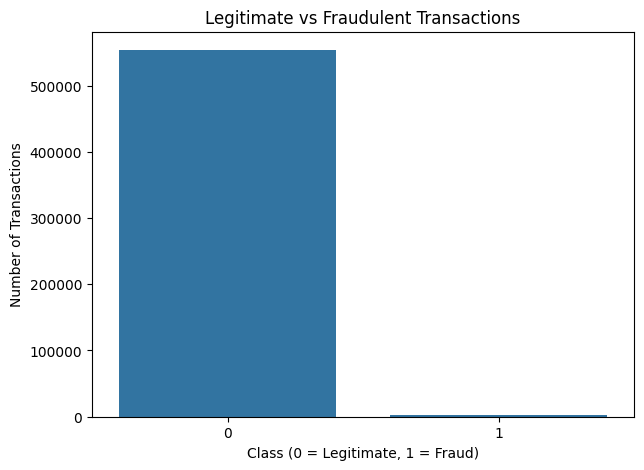

In [7]:
plt.figure(figsize=(7, 5))

sns.countplot(x="Class", data=df)

plt.title("Legitimate vs Fraudulent Transactions")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")

plt.show()

In [9]:
duplicates = df.duplicated().sum()

print("\nNumber of duplicate rows:", duplicates)

if duplicates > 0:
    df = df.drop_duplicates()
    print("Duplicates removed.")
    print("New dataset shape:", df.shape)



Number of duplicate rows: 0


In [10]:
X = df.drop("Class", axis=1)
y = df["Class"]

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)



Feature shape: (555719, 22)
Target shape: (555719,)


In [11]:
scaler = StandardScaler()

# Let's map 'amt' to 'Amount' to maintain compatibility, or scale 'amt' directly
if "amt" in X.columns:
    X = X.rename(columns={"amt": "Amount"})

if "unix_time" in X.columns:
    X = X.rename(columns={"unix_time": "Time"})

# Keep only numeric columns for modeling to avoid categorical format errors
numeric_cols = X.select_dtypes(include=[np.number]).columns.tolist()
X = X[numeric_cols]

# Scale the columns if they exist
if "Amount" in X.columns:
    X["Amount"] = scaler.fit_transform(X[["Amount"]])

if "Time" in X.columns:
    X["Time"] = scaler.fit_transform(X[["Time"]])

# Drop irrelevant numeric columns like 'Unnamed: 0', 'cc_num' or coordinates if present to keep it simple
cols_to_drop = [col for col in ["Unnamed: 0", "cc_num", "zip", "lat", "long", "merch_lat", "merch_long"] if col in X.columns]
X = X.drop(columns=cols_to_drop)

print("\nFeatures kept for training:", X.columns.tolist())
print("Feature scaling completed.")


Features kept for training: ['Amount', 'city_pop', 'Time']
Feature scaling completed.


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\n" + "=" * 60)
print("TRAIN TEST SPLIT")
print("=" * 60)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


TRAIN TEST SPLIT
Training data: (444575, 3)
Testing data: (111144, 3)


In [13]:
print("\n" + "=" * 60)
print("LOGISTIC REGRESSION")
print("=" * 60)

logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

logistic_model.fit(X_train, y_train)

y_pred_lr = logistic_model.predict(X_test)

y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr)
lr_recall = recall_score(y_test, y_pred_lr)
lr_f1 = f1_score(y_test, y_pred_lr)
lr_auc = roc_auc_score(y_test, y_prob_lr)

print("Accuracy :", round(lr_accuracy, 4))
print("Precision:", round(lr_precision, 4))
print("Recall   :", round(lr_recall, 4))
print("F1 Score :", round(lr_f1, 4))
print("ROC-AUC  :", round(lr_auc, 4))



LOGISTIC REGRESSION

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.95      0.97    110715
           1       0.06      0.74      0.10       429

    accuracy                           0.95    111144
   macro avg       0.53      0.84      0.54    111144
weighted avg       1.00      0.95      0.97    111144

Accuracy : 0.9513
Precision: 0.0562
Recall   : 0.7366
F1 Score : 0.1045
ROC-AUC  : 0.8396


In [14]:
print("\n" + "=" * 60)
print("DECISION TREE")
print("=" * 60)

dt_model = DecisionTreeClassifier(
    max_depth=10,
    class_weight="balanced",
    random_state=42
)

dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)

y_prob_dt = dt_model.predict_proba(X_test)[:, 1]

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

dt_accuracy = accuracy_score(y_test, y_pred_dt)
dt_precision = precision_score(y_test, y_pred_dt)
dt_recall = recall_score(y_test, y_pred_dt)
dt_f1 = f1_score(y_test, y_pred_dt)
dt_auc = roc_auc_score(y_test, y_prob_dt)

print("Accuracy :", round(dt_accuracy, 4))
print("Precision:", round(dt_precision, 4))
print("Recall   :", round(dt_recall, 4))
print("F1 Score :", round(dt_f1, 4))
print("ROC-AUC  :", round(dt_auc, 4))



DECISION TREE

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.86      0.93    110715
           1       0.03      0.91      0.05       429

    accuracy                           0.86    111144
   macro avg       0.51      0.89      0.49    111144
weighted avg       1.00      0.86      0.92    111144

Accuracy : 0.8638
Precision: 0.0251
Recall   : 0.9068
F1 Score : 0.0489
ROC-AUC  : 0.9431


In [15]:
print("\n" + "=" * 60)
print("RANDOM FOREST")
print("=" * 60)

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)
rf_auc = roc_auc_score(y_test, y_prob_rf)

print("Accuracy :", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall   :", round(rf_recall, 4))
print("F1 Score :", round(rf_f1, 4))
print("ROC-AUC  :", round(rf_auc, 4))



RANDOM FOREST

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.96      0.98    110715
           1       0.08      0.85      0.14       429

    accuracy                           0.96    111144
   macro avg       0.54      0.91      0.56    111144
weighted avg       1.00      0.96      0.98    111144

Accuracy : 0.9608
Precision: 0.0784
Recall   : 0.8508
F1 Score : 0.1436
ROC-AUC  : 0.9738


In [16]:
print("\n" + "=" * 60)
print("MODEL COMPARISON")
print("=" * 60)

results = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],

    "Accuracy": [
        lr_accuracy,
        dt_accuracy,
        rf_accuracy
    ],

    "Precision": [
        lr_precision,
        dt_precision,
        rf_precision
    ],

    "Recall": [
        lr_recall,
        dt_recall,
        rf_recall
    ],

    "F1 Score": [
        lr_f1,
        dt_f1,
        rf_f1
    ],

    "ROC-AUC": [
        lr_auc,
        dt_auc,
        rf_auc
    ]
})

print("\n")
print(results.round(4).to_string(index=False))


MODEL COMPARISON


              Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
Logistic Regression    0.9513     0.0562  0.7366    0.1045   0.8396
      Decision Tree    0.8638     0.0251  0.9068    0.0489   0.9431
      Random Forest    0.9608     0.0784  0.8508    0.1436   0.9738


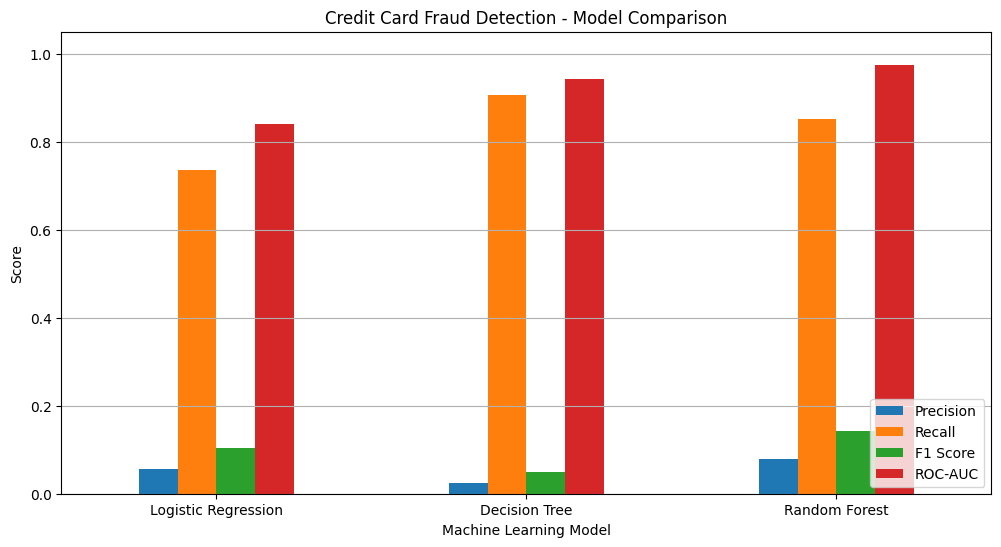

In [17]:
results_plot = results.set_index("Model")

results_plot[
    ["Precision", "Recall", "F1 Score", "ROC-AUC"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Credit Card Fraud Detection - Model Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y")

plt.show()



RANDOM FOREST CONFUSION MATRIX
[[106424   4291]
 [    64    365]]


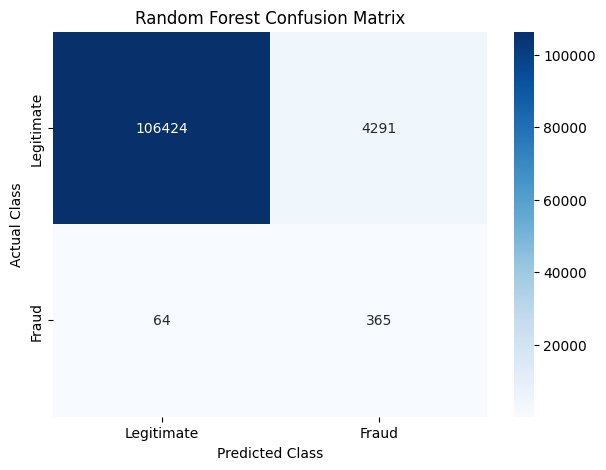

In [18]:
print("\n" + "=" * 60)
print("RANDOM FOREST CONFUSION MATRIX")
print("=" * 60)

cm = confusion_matrix(y_test, y_pred_rf)

print(cm)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()

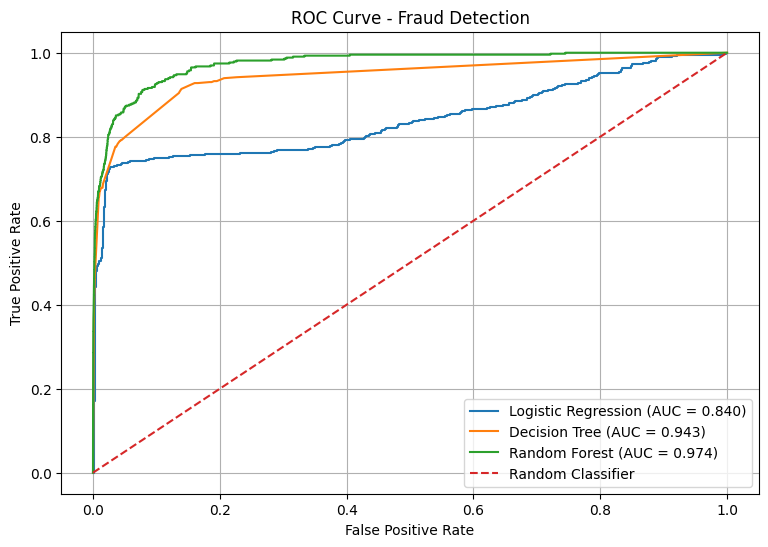

In [19]:
fpr_lr, tpr_lr, _ = roc_curve(
    y_test,
    y_prob_lr
)

fpr_dt, tpr_dt, _ = roc_curve(
    y_test,
    y_prob_dt
)

fpr_rf, tpr_rf, _ = roc_curve(
    y_test,
    y_prob_rf
)

plt.figure(figsize=(9, 6))

plt.plot(
    fpr_lr,
    tpr_lr,
    label=f"Logistic Regression (AUC = {lr_auc:.3f})"
)

plt.plot(
    fpr_dt,
    tpr_dt,
    label=f"Decision Tree (AUC = {dt_auc:.3f})"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC = {rf_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve - Fraud Detection")

plt.legend()
plt.grid()

plt.show()


FEATURE IMPORTANCE
 Feature  Importance
  Amount    0.815923
    Time    0.106783
city_pop    0.077295


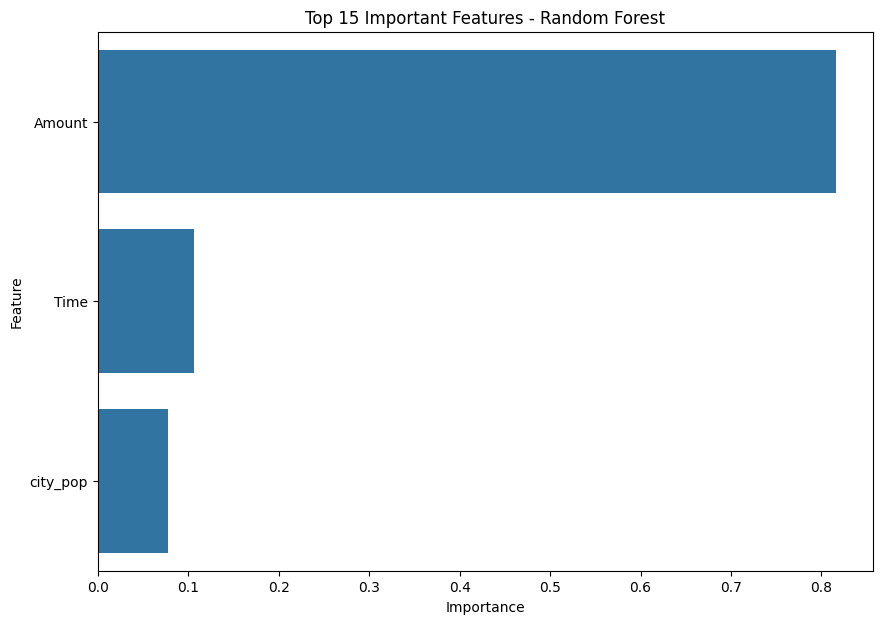

In [20]:
print("\n" + "=" * 60)
print("FEATURE IMPORTANCE")
print("=" * 60)

feature_importance = pd.DataFrame({

    "Feature": X.columns,

    "Importance": rf_model.feature_importances_

})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(
    feature_importance.head(15).to_string(
        index=False
    )
)


# Plot top 15 features

plt.figure(figsize=(10, 7))

sns.barplot(
    x="Importance",
    y="Feature",
    data=feature_importance.head(15)
)

plt.title("Top 15 Important Features - Random Forest")

plt.show()


In [21]:
print("\n" + "=" * 60)
print("SAMPLE FRAUD PREDICTION")
print("=" * 60)

sample = X_test.iloc[[0]]

prediction = rf_model.predict(sample)[0]

fraud_probability = rf_model.predict_proba(
    sample
)[0][1]

print("\nFraud Probability:",
      round(fraud_probability * 100, 2), "%")

if prediction == 1:

    print("Prediction: FRAUDULENT TRANSACTION")

else:

    print("Prediction: LEGITIMATE TRANSACTION")


SAMPLE FRAUD PREDICTION

Fraud Probability: 0.0 %
Prediction: LEGITIMATE TRANSACTION


In [22]:
joblib.dump(
    rf_model,
    "credit_card_fraud_random_forest.pkl"
)

joblib.dump(
    scaler,
    "credit_card_scaler.pkl"
)

print("\n" + "=" * 60)
print("MODEL SAVED")
print("=" * 60)

print(
    "credit_card_fraud_random_forest.pkl"
)

print(
    "credit_card_scaler.pkl"
)


MODEL SAVED
credit_card_fraud_random_forest.pkl
credit_card_scaler.pkl


In [23]:
best_model = results.loc[
    results["F1 Score"].idxmax(),
    "Model"
]

print("\n" + "=" * 60)
print("FINAL RESULT")
print("=" * 60)

print(
    "Best model based on F1 Score:",
    best_model
)

print("\nProject completed successfully!")


FINAL RESULT
Best model based on F1 Score: Random Forest

Project completed successfully!
